<a href="https://colab.research.google.com/github/deepak-kumar-da/smart-comment-classifier/blob/main/notebooks/05_model_evaluation_and_error_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q iterative-stratification

from google.colab import drive
drive.mount('/content/drive',force_remount=True)

import os
import json
import pickle
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score,precision_score,recall_score,f1_score,multilabel_confusion_matrix
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

BASE = "/content/drive/MyDrive/Smart_Comment_Classifier"

RAW = f"{BASE}/datasets/raw"
PROCESSED = f"{BASE}/datasets/processed"
REPORTS = f"{BASE}/datasets/reports"
MODELS = f"{BASE}/datasets/models"
OUTPUTS = f"{BASE}/datasets/outputs"

os.makedirs(REPORTS,exist_ok=True)
os.makedirs(MODELS,exist_ok=True)

Mounted at /content/drive


In [ ]:
# load processed datasets

uci = pd.read_csv(f"{PROCESSED}/uci_spam_final.csv")
youtube_spam = pd.read_csv(f"{PROCESSED}/youtube_spam_final.csv")
jigsaw = pd.read_csv(f"{PROCESSED}/jigsaw_toxicity_final.csv")
youtube_toxicity = pd.read_csv(f"{PROCESSED}/youtube_toxicity_final.csv")

print("UCI spam",uci.shape)
print("Youtube spam",youtube_spam.shape)
print("Jigsaw",jigsaw.shape)
print("Youtube toxicity",youtube_toxicity.shape)

UCI spam (1741, 4)
Youtube spam (14032, 4)
Jigsaw (159272, 9)
Youtube toxicity (14034, 4)


In [ ]:
# load models

import joblib

spam_vectorizer = joblib.load(f"{MODELS}/spam_tfidf_vectorizer.pkl")
toxicity_vectorizer = joblib.load(f"{MODELS}/toxicity_tfidf_vectorizer.pkl")

In [ ]:
spam_model_path = f"{MODELS}/spam_classical_models.pkl"

toxicity_candidates = [
    f"{MODELS}/toxicity_classical_models.pkl",
    f"{MODELS}/toxicity_classical_models.pkl"
]

toxicity_model_path = next(
    (p for p in toxicity_candidates if os.path.exists(p)),
    None
)

if not os.path.exists(spam_model_path):
  raise FileNotFoundError(spam_model_path)

if toxicity_model_path is None:
  raise FileNotFoundError("Could not find the toxicity model bundle")

spam_models = joblib.load(spam_model_path)
toxicity_models = joblib.load(toxicity_model_path)

print("Spam models",list(spam_models.keys()))
print("Toxicity models",list(toxicity_models.keys()))
print("Toxicity bundle path",toxicity_model_path)

Spam models ['Naive Bayes', 'Logistics Regression', 'Linear SVM']
Toxicity models ['Naive Bayes', 'Logistics Regression', 'Linear SVM']
Toxicity bundle path /content/drive/MyDrive/Smart_Comment_Classifier/datasets/models/toxicity_classical_models.pkl


In [ ]:
# model bundle structure

print("Spam Model Structure")

for name,model in spam_models.items():
  print(name,":",type(model))

print("Toxicity Model Structure")

for name,model in toxicity_models.items():
  print(name,":",type(model))

print("Vectorizer feature counts")
print("Spam",len(spam_vectorizer.get_feature_names_out()))
print("Toxicity",len(toxicity_vectorizer.get_feature_names_out()))

Spam Model Structure
Naive Bayes : <class 'sklearn.naive_bayes.MultinomialNB'>
Logistics Regression : <class 'sklearn.linear_model._logistic.LogisticRegression'>
Linear SVM : <class 'sklearn.svm._classes.LinearSVC'>
Toxicity Model Structure
Naive Bayes : <class 'dict'>
Logistics Regression : <class 'dict'>
Linear SVM : <class 'dict'>
Vectorizer feature counts
Spam 3524
Toxicity 200000


In [ ]:
toxicity_labels = [
    "toxic",
    "severe_toxic",
    "obscene",
    "threat",
    "insult",
    "identity_hate"
]

missing = [
    col for col in toxicity_labels
    if col not in jigsaw.columns
]

if missing:
  raise ValueError(f"Missing toxicity columns: {missing}")

In [ ]:
uci_eval = uci.copy()

uci_eval["label"] = pd.to_numeric(uci_eval["label"],errors="coerce")
uci_eval = uci_eval.dropna(subset=["text","label"])
uci_eval["label"] = uci_eval["label"].astype(int)

X_spam = uci_eval["text"].astype(str)
y_spam = uci_eval["label"]

X_spam_train, X_spam_test, y_spam_train, y_spam_test = train_test_split(
    X_spam,
    y_spam,
    test_size=0.2,
    random_state=42,
    stratify=y_spam
)

print("Spam training records",len(X_spam_train))
print("Spam testing records",len(X_spam_test))
print("Test Distribution")
print(y_spam_test.value_counts())



Spam training records 1392
Spam testing records 349
Test Distribution
label
0    181
1    168
Name: count, dtype: int64


In [ ]:
# toxicity test split

X_toxicity = jigsaw["text"].astype(str)
y_toxicity = jigsaw[toxicity_labels].astype(int)

splitter = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx,test_idx = next(splitter.split(X_toxicity,y_toxicity))

X_toxicity_train = X_toxicity.iloc[train_idx]
X_toxicity_test = X_toxicity.iloc[test_idx]

y_toxicity_train = y_toxicity.iloc[train_idx]
y_toxicity_test = y_toxicity.iloc[test_idx]

print("Toxicity training records",len(X_toxicity_train))
print("Toxicity testing records",len(X_toxicity_test))
print("Test Distribution")
print(y_toxicity_test.sum().to_frame("Positive samples"))

Toxicity training records 127417
Toxicity testing records 31855
Test Distribution
               Positive samples
toxic                      3043
severe_toxic                317
obscene                    1681
threat                       94
insult                     1567
identity_hate               279


In [ ]:
# transform test data

X_spam_test_vec = spam_vectorizer.transform(X_spam_test)
X_toxicity_test_vec = toxicity_vectorizer.transform(X_toxicity_test)

print("Spam test vector shape",X_spam_test_vec.shape)
print("Toxicity test vector shape",X_toxicity_test_vec.shape)

Spam test vector shape (349, 3524)
Toxicity test vector shape (31855, 200000)


In [ ]:
def inspect_bundle(bundle,bundle_name):

  print("\n","="*50)
  print(bundle_name)
  print("="*50)

  for name,model in bundle.items():
    print("\nModel",name)
    print("Object type",type(model))

    if isinstance(model,dict):
      print("Nested keys",list(model.keys()))

    elif isinstance(model,(list,tuple)):
      print("Number of stored models",len(model))

    elif hasattr(model,"estimators_"):
      print("Number of estimators",len(model.estimators_))

inspect_bundle(spam_models,"Spam models")
inspect_bundle(toxicity_models,"Toxicity models")


Spam models

Model Naive Bayes
Object type <class 'sklearn.naive_bayes.MultinomialNB'>

Model Logistics Regression
Object type <class 'sklearn.linear_model._logistic.LogisticRegression'>

Model Linear SVM
Object type <class 'sklearn.svm._classes.LinearSVC'>

Toxicity models

Model Naive Bayes
Object type <class 'dict'>
Nested keys ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Model Logistics Regression
Object type <class 'dict'>
Nested keys ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']

Model Linear SVM
Object type <class 'dict'>
Nested keys ['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']


In [ ]:
# spam model evaluation

spam_predictions = {}

for name,model in spam_models.items():
  predictions = model.predict(X_spam_test_vec)
  predictions = np.asarray(predictions).reshape(-1)
  if len(predictions) != len(y_spam_test):
    raise ValueError(f"Prediction length mismatch for {name}")
  spam_predictions[name] = predictions

print("Spam predictions")

for name,predictions in spam_predictions.items():
  print(name,":",len(predictions))


Spam predictions
Naive Bayes : 349
Logistics Regression : 349
Linear SVM : 349


In [ ]:
spam_reports = {}
spam_metrics = []

for name,predictions in spam_predictions.items():
  print("\n" + "="*50)
  print("MODEL: ",name)
  print("="*50)

  print(classification_report(
      y_spam_test,
      predictions,
      labels=[0,1],
      target_names=["Not Spam","Spam"],
      digits=4,
      zero_division=0
  ))

  spam_reports[name] = classification_report(
      y_spam_test,
      predictions,
      labels=[0,1],
      target_names=["Not Spam","Spam"],
      output_dict=True,
      zero_division=0
  )

  spam_metrics.append({
      "Model":name,
      "Accuracy":accuracy_score(y_spam_test,predictions),
      "Precision_Macro":precision_score(y_spam_test,predictions,average="macro",zero_division=0),
      "Recall_Macro":recall_score(y_spam_test,predictions,average="macro",zero_division=0),
      "F1_Macro":f1_score(y_spam_test,predictions,average="macro",zero_division=0),
      "Spam_Precision":precision_score(y_spam_test,predictions,pos_label=1,zero_division=0),
      "Spam_Recall":recall_score(y_spam_test,predictions,pos_label=1,zero_division=0),
      "Spam_F1":f1_score(y_spam_test,predictions,pos_label=1,zero_division=0)
  })

spam_metrics_df = pd.DataFrame(spam_metrics)

display(spam_metrics_df.sort_values("F1_Macro",ascending=False).round(4))


MODEL:  Naive Bayes
              precision    recall  f1-score   support

    Not Spam     0.9198    0.9503    0.9348       181
        Spam     0.9444    0.9107    0.9273       168

    accuracy                         0.9312       349
   macro avg     0.9321    0.9305    0.9310       349
weighted avg     0.9317    0.9312    0.9312       349


MODEL:  Logistics Regression
              precision    recall  f1-score   support

    Not Spam     0.9275    0.9890    0.9572       181
        Spam     0.9872    0.9167    0.9506       168

    accuracy                         0.9542       349
   macro avg     0.9573    0.9528    0.9539       349
weighted avg     0.9562    0.9542    0.9540       349


MODEL:  Linear SVM
              precision    recall  f1-score   support

    Not Spam     0.9516    0.9779    0.9646       181
        Spam     0.9755    0.9464    0.9607       168

    accuracy                         0.9628       349
   macro avg     0.9635    0.9622    0.9627       349
wei

,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Spam_Precision,Spam_Recall,Spam_F1
2,Linear SVM,0.9628,0.9635,0.9622,0.9627,0.9755,0.9464,0.9607
1,Logistics Regression,0.9542,0.9573,0.9528,0.9539,0.9872,0.9167,0.9506
0,Naive Bayes,0.9312,0.9321,0.9305,0.9310,0.9444,0.9107,0.9273


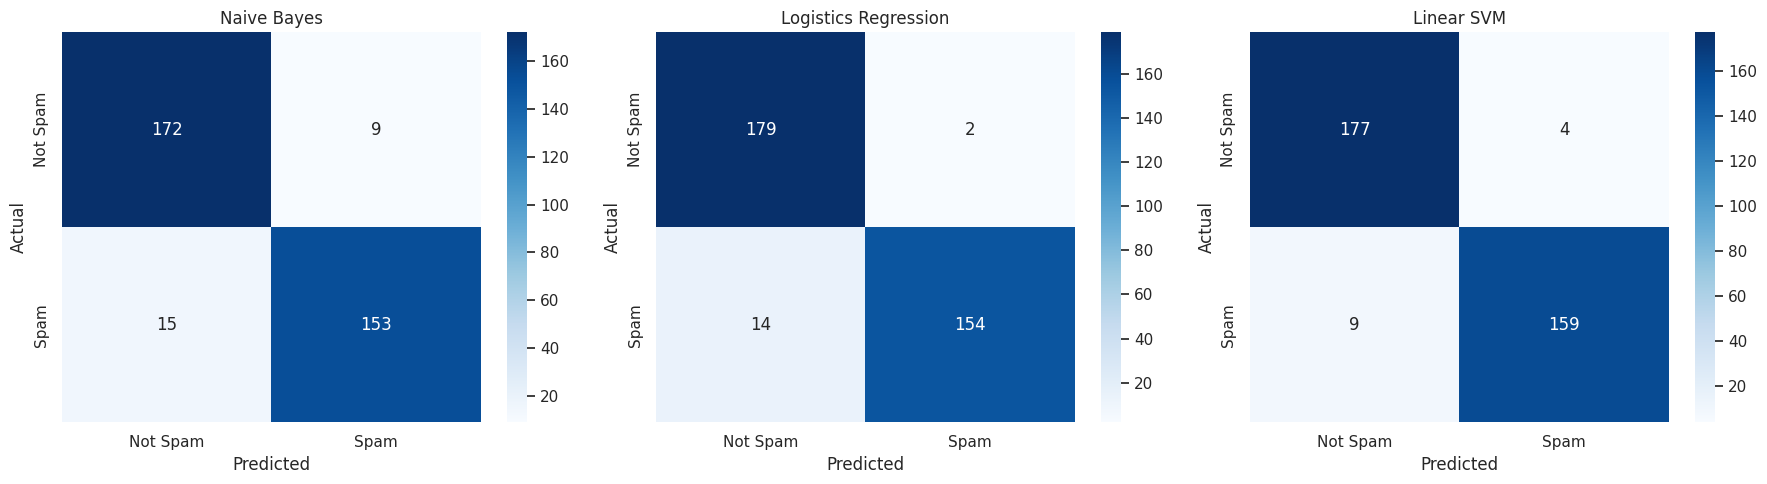

In [ ]:
# Spam Confusion Matrix

fig,axes = plt.subplots(
    1, len(spam_predictions),
    figsize=(6*len(spam_predictions),5)
)

if len(spam_predictions) == 1:
  axes = [axes]

for ax,(name,predictions) in zip(axes,spam_predictions.items()):
  cm = confusion_matrix(y_spam_test,predictions,labels=[0,1])
  sns.heatmap(
      cm,
      annot=True,
      fmt="d",
      cmap="Blues",
      xticklabels=["Not Spam","Spam"],
      yticklabels=["Not Spam","Spam"],
      ax=ax
  )

  ax.set_title(name)
  ax.set_xlabel("Predicted")
  ax.set_ylabel("Actual")

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/notebook05_spam_confusion_matrices.png",dpi=300,bbox_inches="tight")
plt.show()

In [ ]:
# Spam false positive & false negative

spam_error_frames = {}

for name,predictions in spam_predictions.items():
  errors = pd.DataFrame({
      "text":X_spam_test.values,
      "actual":y_spam_test.values,
      "predicted":predictions
  })

  errors["error_type"] = np.select(
      [
          (errors["actual"] == 0) & (errors["predicted"] == 1),
          (errors["actual"] == 1) & (errors["predicted"] == 0)
      ],
      [
          "False Positive",
          "False Negative"
      ],
      default="Correct"
  )

  error_only = errors[errors["error_type"] != "Correct"].copy()

  spam_error_frames[name] = error_only

  print("\n" ,name)
  print(error_only["error_type"].value_counts())

  error_only.to_csv(f"{OUTPUTS}/spam_errors_{name.replace('',"_")}.csv",index=False)


 Naive Bayes
error_type
False Negative    15
False Positive     9
Name: count, dtype: int64

 Logistics Regression
error_type
False Negative    14
False Positive     2
Name: count, dtype: int64

 Linear SVM
error_type
False Negative    9
False Positive    4
Name: count, dtype: int64


In [ ]:
# toxicity model evaluation

def predict_multilabel(model_object, X, label_names):
    """
    Supports:
    - Estimators returning multi-label predictions
    - MultiOutputClassifier / OneVsRestClassifier
    - Dictionaries mapping labels to estimators
    - Lists/tuples of one estimator per label
    """

    n_labels = len(label_names)

    # Case 1: Dictionary containing individual label models
    if isinstance(model_object, dict):

        normalized = {
            str(k).strip().lower(): v
            for k, v in model_object.items()
        }

        if all(label.lower() in normalized for label in label_names):

            columns = []

            for label in label_names:
                estimator = normalized[label.lower()]
                columns.append(
                    np.asarray(estimator.predict(X)).reshape(-1)
                )

            return np.column_stack(columns)

        raise ValueError(
            "Dictionary does not contain all six named label models. "
            f"Found keys: {list(model_object.keys())}"
        )

    # Case 2: List or tuple containing six estimators
    if isinstance(model_object, (list, tuple)):

        if len(model_object) != n_labels:
            raise ValueError(
                f"Expected {n_labels} models, found {len(model_object)}"
            )

        columns = [
            np.asarray(estimator.predict(X)).reshape(-1)
            for estimator in model_object
        ]

        return np.column_stack(columns)

    # Case 3: sklearn multi-output estimator
    predictions = np.asarray(model_object.predict(X))

    if predictions.ndim == 2 and predictions.shape[1] == n_labels:
        return predictions

    # Case 4: estimator with one binary estimator per label
    if hasattr(model_object, "estimators_"):

        estimators = model_object.estimators_

        if len(estimators) == n_labels:

            columns = [
                np.asarray(estimator.predict(X)).reshape(-1)
                for estimator in estimators
            ]

            return np.column_stack(columns)

    raise ValueError(
        "Unsupported toxicity model structure. "
        f"Object type: {type(model_object)}. "
        f"Prediction shape: {predictions.shape}"
    )

In [ ]:
toxicity_predictions = {}

for model_name, model_object in toxicity_models.items():

    print("Evaluating:", model_name)

    predictions = predict_multilabel(
        model_object,
        X_toxicity_test_vec,
        toxicity_labels
    )

    if predictions.shape != y_toxicity_test.shape:
        raise ValueError(
            f"Shape mismatch for {model_name}: "
            f"{predictions.shape} vs {y_toxicity_test.shape}"
        )

    toxicity_predictions[model_name] = predictions.astype(int)

print("\nAll toxicity predictions generated.")

for name, predictions in toxicity_predictions.items():
    print(name, predictions.shape)

Evaluating: Naive Bayes
Evaluating: Logistics Regression
Evaluating: Linear SVM

All toxicity predictions generated.
Naive Bayes (31855, 6)
Logistics Regression (31855, 6)
Linear SVM (31855, 6)


In [ ]:
# Classification Report

toxicity_reports = {}
toxicity_metrics = []

for model_name, predictions in toxicity_predictions.items():

    print("\n" + "=" * 70)
    print("MODEL:", model_name)
    print("=" * 70)

    report = classification_report(
        y_toxicity_test,
        predictions,
        target_names=toxicity_labels,
        output_dict=True,
        zero_division=0
    )

    print(classification_report(
        y_toxicity_test,
        predictions,
        target_names=toxicity_labels,
        digits=4,
        zero_division=0
    ))

    toxicity_reports[model_name] = report

    for label in toxicity_labels:

        toxicity_metrics.append({
            "Model": model_name,
            "Label": label,
            "Precision": report[label]["precision"],
            "Recall": report[label]["recall"],
            "F1": report[label]["f1-score"],
            "Support": report[label]["support"]
        })

toxicity_metrics_df = pd.DataFrame(toxicity_metrics)

display(
    toxicity_metrics_df.round(4)
)


MODEL: Naive Bayes
               precision    recall  f1-score   support

        toxic     0.9612    0.4154    0.5801      3043
 severe_toxic     0.8750    0.0221    0.0431       317
      obscene     0.9285    0.3474    0.5056      1681
       threat     0.0000    0.0000    0.0000        94
       insult     0.8687    0.2744    0.4171      1567
identity_hate     0.0000    0.0000    0.0000       279

    micro avg     0.9334    0.3273    0.4847      6981
    macro avg     0.6056    0.1765    0.2576      6981
 weighted avg     0.8773    0.3273    0.4702      6981
  samples avg     0.0385    0.0258    0.0292      6981


MODEL: Logistics Regression
               precision    recall  f1-score   support

        toxic     0.6525    0.8429    0.7356      3043
 severe_toxic     0.3095    0.8454    0.4531       317
      obscene     0.6949    0.8846    0.7783      1681
       threat     0.2085    0.7340    0.3247        94
       insult     0.5747    0.8596    0.6888      1567
identity_hat

,Model,Label,Precision,Recall,F1,Support
0,Naive Bayes,toxic,0.9612,0.4154,0.5801,3043.0
1,Naive Bayes,severe_toxic,0.8750,0.0221,0.0431,317.0
2,Naive Bayes,obscene,0.9285,0.3474,0.5056,1681.0
3,Naive Bayes,threat,0.0000,0.0000,0.0000,94.0
4,Naive Bayes,insult,0.8687,0.2744,0.4171,1567.0
5,Naive Bayes,identity_hate,0.0000,0.0000,0.0000,279.0
6,Logistics Regression,toxic,0.6525,0.8429,0.7356,3043.0
7,Logistics Regression,severe_toxic,0.3095,0.8454,0.4531,317.0
8,Logistics Regression,obscene,0.6949,0.8846,0.7783,1681.0
9,Logistics Regression,threat,0.2085,0.7340,0.3247,94.0


In [ ]:
# Model Comparison

toxicity_overall = []

for model_name, predictions in toxicity_predictions.items():

    toxicity_overall.append({
        "Model": model_name,

        "Micro_F1": f1_score(
            y_toxicity_test,
            predictions,
            average="micro",
            zero_division=0
        ),

        "Macro_F1": f1_score(
            y_toxicity_test,
            predictions,
            average="macro",
            zero_division=0
        ),

        "Weighted_F1": f1_score(
            y_toxicity_test,
            predictions,
            average="weighted",
            zero_division=0
        ),

        "Micro_Precision": precision_score(
            y_toxicity_test,
            predictions,
            average="micro",
            zero_division=0
        ),

        "Micro_Recall": recall_score(
            y_toxicity_test,
            predictions,
            average="micro",
            zero_division=0
        ),

        "Exact_Match_Accuracy": accuracy_score(
            y_toxicity_test,
            predictions
        )
    })

toxicity_overall_df = pd.DataFrame(toxicity_overall)

display(
    toxicity_overall_df.sort_values(
        "Macro_F1", ascending=False
    ).round(4)
)

,Model,Micro_F1,Macro_F1,Weighted_F1,Micro_Precision,Micro_Recall,Exact_Match_Accuracy
2,Linear SVM,0.7381,0.6057,0.7393,0.7215,0.7555,0.9109
1,Logistics Regression,0.6845,0.5607,0.7030,0.5731,0.8496,0.8823
0,Naive Bayes,0.4847,0.2576,0.4702,0.9334,0.3273,0.9076


Model,Linear SVM,Logistics Regression,Naive Bayes
Label,,,
identity_hate,0.4328,0.3839,0.0000
insult,0.7172,0.6888,0.4171
obscene,0.8026,0.7783,0.5056
severe_toxic,0.4810,0.4531,0.0431
threat,0.4198,0.3247,0.0000
toxic,0.7806,0.7356,0.5801


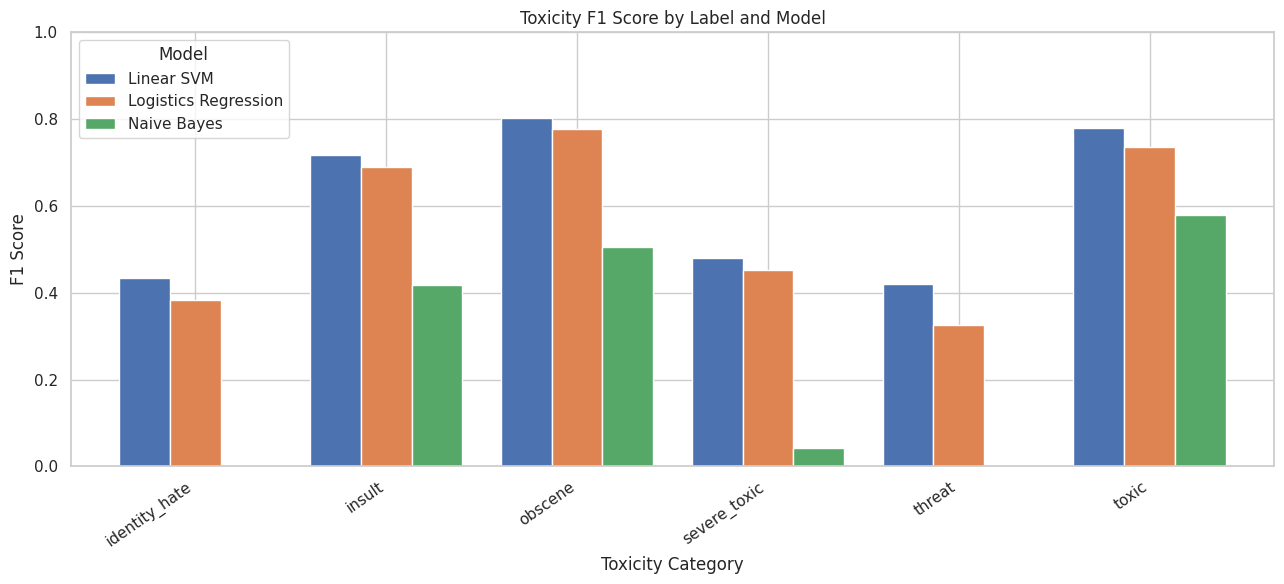

In [ ]:
# f1 comparison

f1_pivot = toxicity_metrics_df.pivot(
    index="Label",
    columns="Model",
    values="F1"
)

display(f1_pivot.round(4))

f1_pivot.plot(
    kind="bar",
    figsize=(13, 6),
    ylim=(0, 1),
    width=0.8
)

plt.title("Toxicity F1 Score by Label and Model")
plt.ylabel("F1 Score")
plt.xlabel("Toxicity Category")
plt.xticks(rotation=35, ha="right")
plt.legend(title="Model")
plt.tight_layout()

plt.savefig(
    f"{OUTPUTS}/notebook05_toxicity_per_label_f1.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

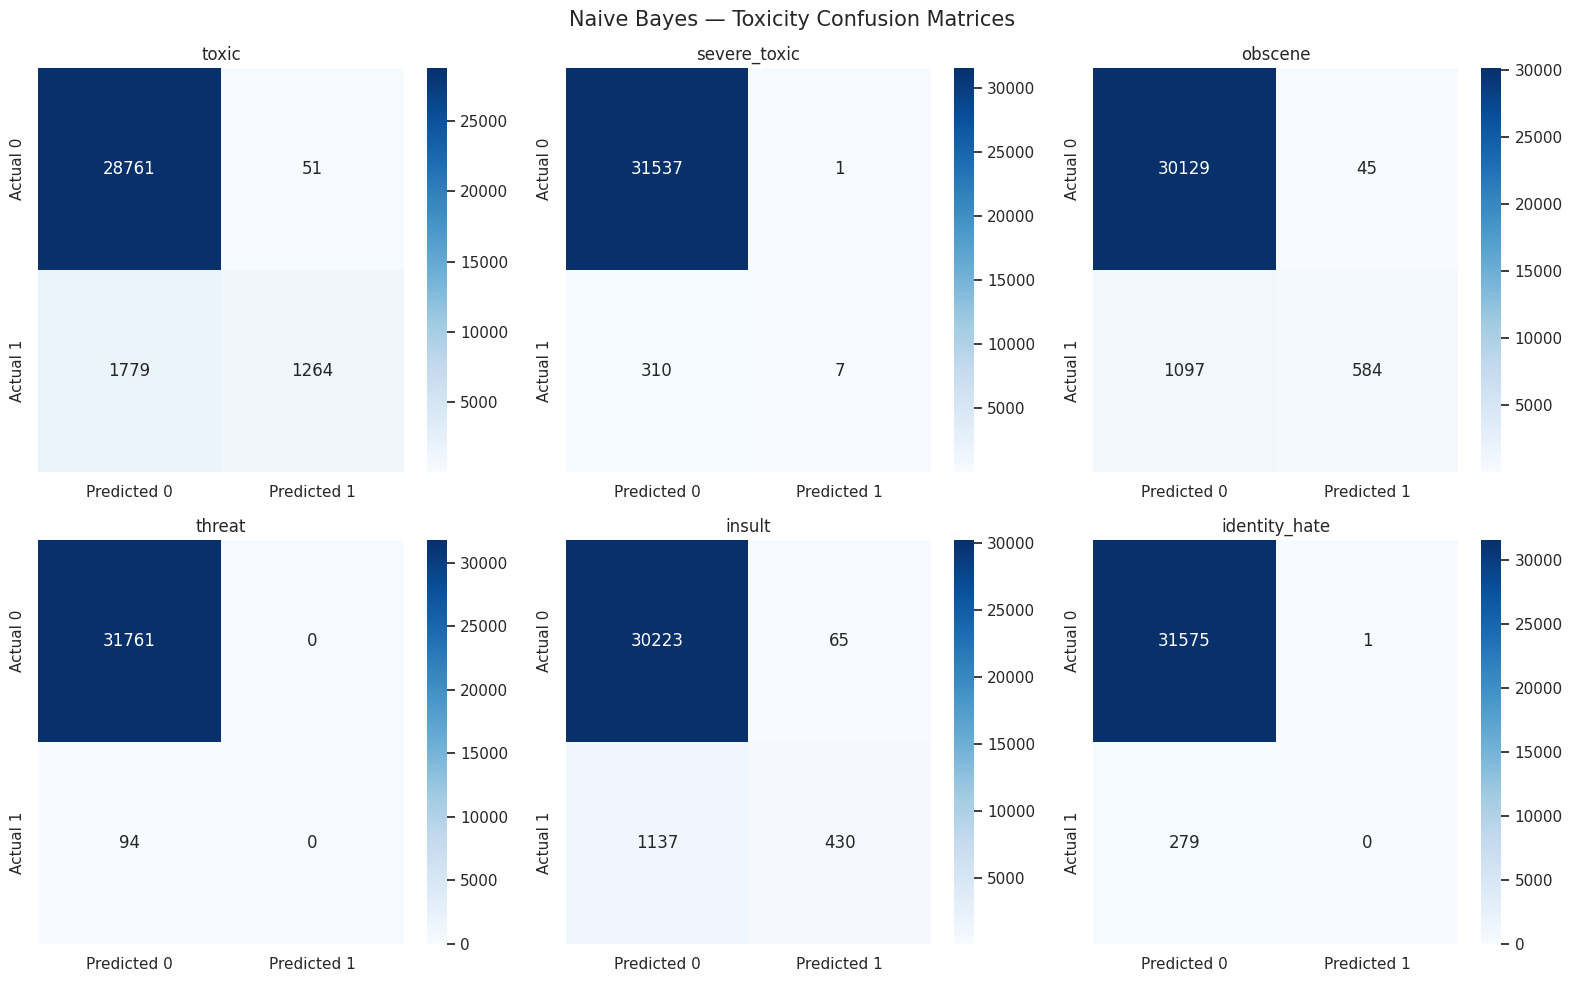

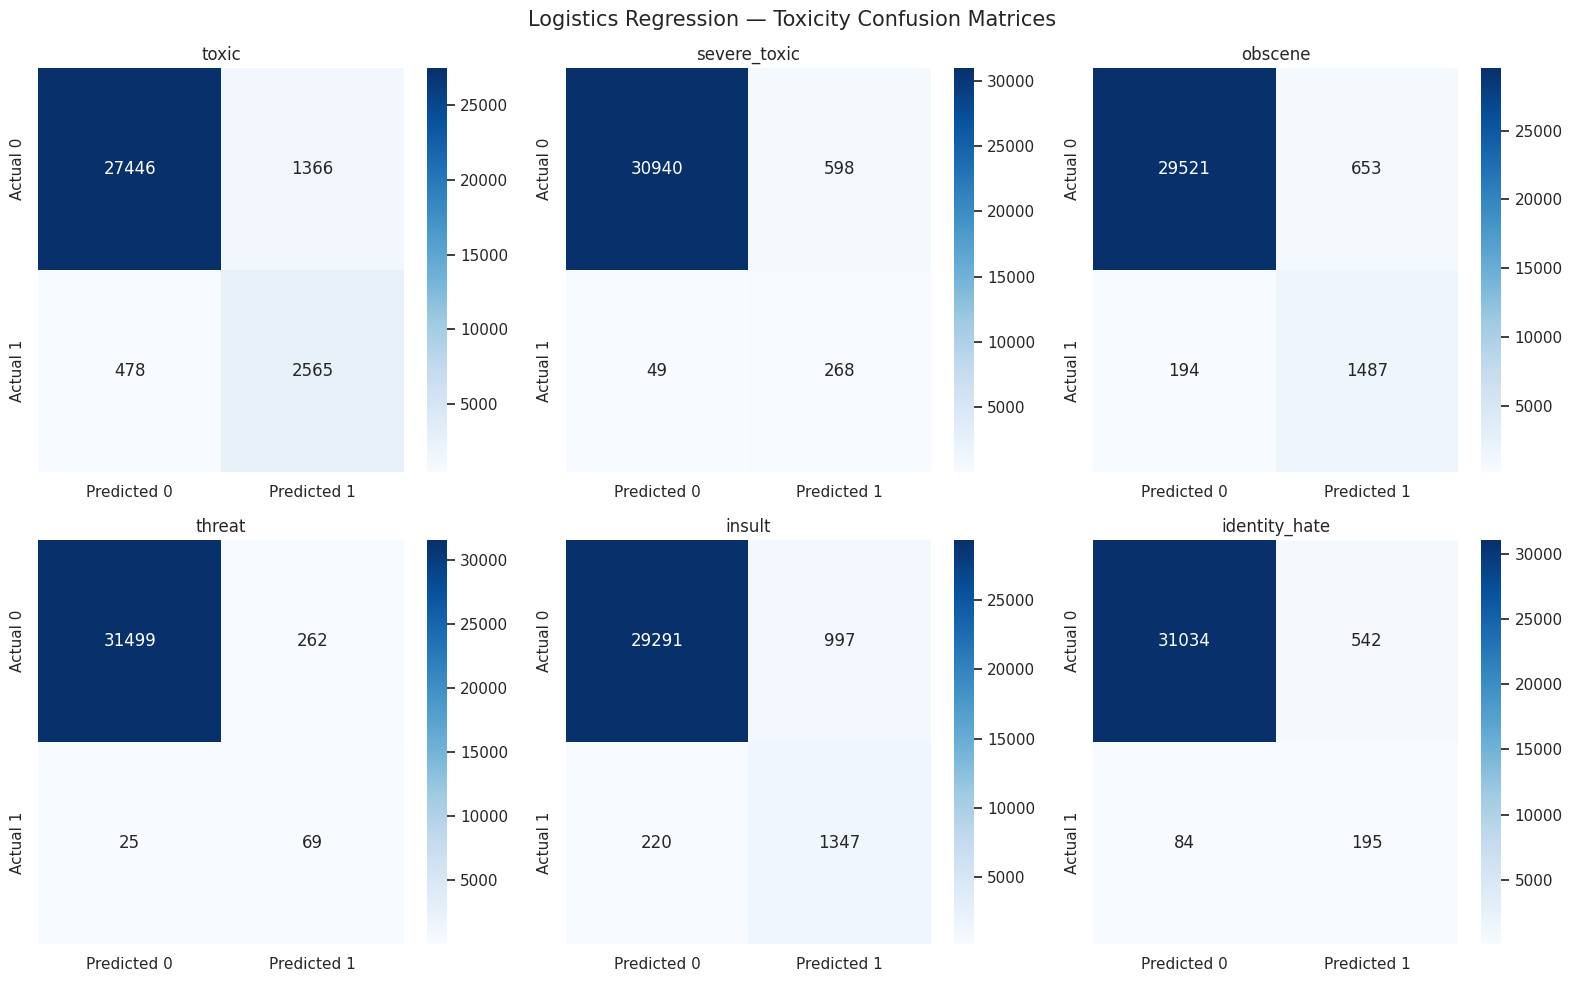

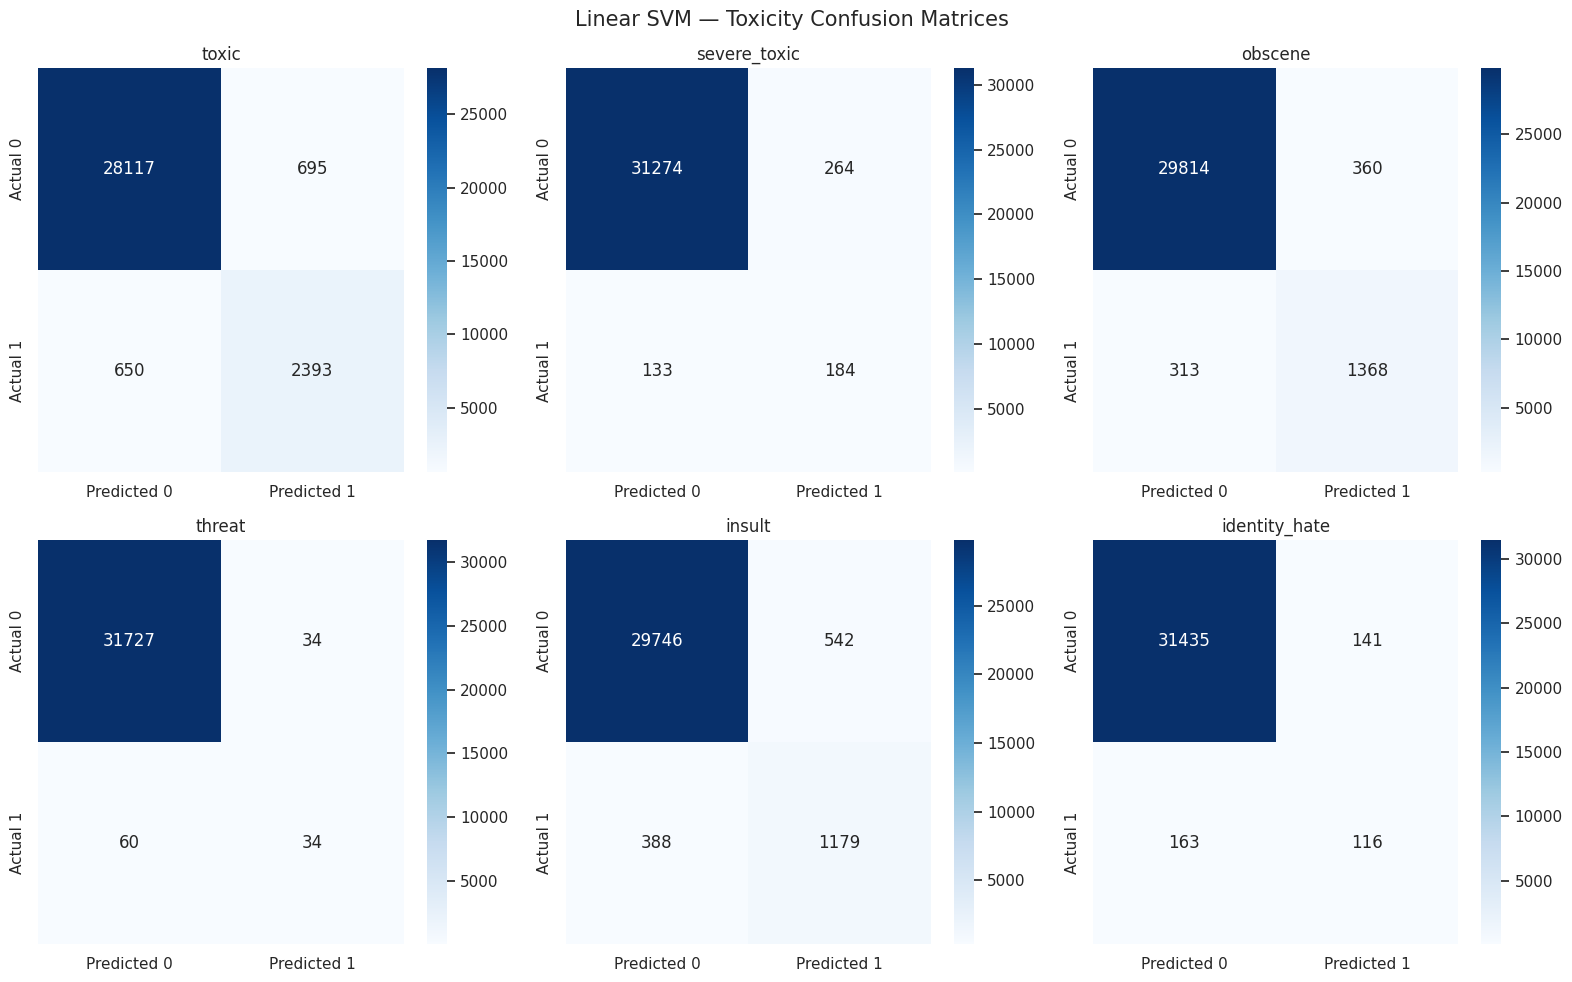

In [ ]:
# six-label confusion  matrix

for model_name, predictions in toxicity_predictions.items():

    matrices = multilabel_confusion_matrix(
        y_toxicity_test,
        predictions
    )

    fig, axes = plt.subplots(
        2, 3,
        figsize=(16, 10)
    )

    for i, ax in enumerate(axes.flat):

        sns.heatmap(
            matrices[i],
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=["Predicted 0", "Predicted 1"],
            yticklabels=["Actual 0", "Actual 1"],
            ax=ax
        )

        ax.set_title(toxicity_labels[i])

    fig.suptitle(
        f"{model_name} — Toxicity Confusion Matrices",
        fontsize=15
    )

    plt.tight_layout()

    filename = (
        f"toxicity_confusion_"
        f"{model_name.replace(' ', '_')}.png"
    )

    plt.savefig(
        f"{OUTPUTS}/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

In [ ]:
# Toxicity error analysis - false positive and false negative

toxicity_error_frames = {}

for model_name, predictions in toxicity_predictions.items():

    error_records = []

    for i, label in enumerate(toxicity_labels):

        actual = y_toxicity_test.iloc[:, i].values
        predicted = predictions[:, i]

        fp_indices = np.where(
            (actual == 0) & (predicted == 1)
        )[0]

        fn_indices = np.where(
            (actual == 1) & (predicted == 0)
        )[0]

        for idx in fp_indices:

            error_records.append({
                "text": X_toxicity_test.iloc[idx],
                "label": label,
                "actual": 0,
                "predicted": 1,
                "error_type": "False Positive"
            })

        for idx in fn_indices:

            error_records.append({
                "text": X_toxicity_test.iloc[idx],
                "label": label,
                "actual": 1,
                "predicted": 0,
                "error_type": "False Negative"
            })

    error_df = pd.DataFrame(error_records)

    toxicity_error_frames[model_name] = error_df

    filename = (
        f"toxicity_errors_"
        f"{model_name.replace(' ', '_')}.csv"
    )

    error_df.to_csv(
        f"{OUTPUTS}/{filename}",
        index=False
    )

    print("\n", model_name)
    print(error_df["error_type"].value_counts())

print("\nToxicity error samples saved.")


 Naive Bayes
error_type
False Negative    4696
False Positive     163
Name: count, dtype: int64

 Logistics Regression
error_type
False Positive    4418
False Negative    1050
Name: count, dtype: int64

 Linear SVM
error_type
False Positive    2036
False Negative    1707
Name: count, dtype: int64

Toxicity error samples saved.


In [ ]:
# error counts by category

for model_name, error_df in toxicity_error_frames.items():

    print("\nMODEL:", model_name)

    if error_df.empty:
        print("No classification errors found.")
        continue

    error_summary = pd.crosstab(
        error_df["label"],
        error_df["error_type"]
    )

    display(error_summary)


MODEL: Naive Bayes


error_type,False Negative,False Positive
label,,
identity_hate,279,1
insult,1137,65
obscene,1097,45
severe_toxic,310,1
threat,94,0
toxic,1779,51



MODEL: Logistics Regression


error_type,False Negative,False Positive
label,,
identity_hate,84,542
insult,220,997
obscene,194,653
severe_toxic,49,598
threat,25,262
toxic,478,1366



MODEL: Linear SVM


error_type,False Negative,False Positive
label,,
identity_hate,163,141
insult,388,542
obscene,313,360
severe_toxic,133,264
threat,60,34
toxic,650,695


In [ ]:
for model_name, error_df in spam_error_frames.items():

    print("\nMODEL:", model_name)

    display(
        error_df[
            ["text", "actual", "predicted", "error_type"]
        ].head(15)
    )


MODEL: Naive Bayes


,text,actual,predicted,error_type
7,On 0:02 u can see the camera man on his glasse...,0,1,False Positive
66,Hay dakota u earned a subscribee,1,0,False Negative
68,like this comment if your watching in 2015 or ...,1,0,False Negative
70,"Part 5. Comforter of the afflicted, pray for u...",1,0,False Negative
80,IIIIIIIIIII LOVE THIS SHAKE IT SONG OH SORRY E...,1,0,False Negative
83,Subscribe and u are gonna hear me roar ;)﻿,1,0,False Negative
109,Yea stil the best WK song ever<br />Thumbs up ...,1,0,False Negative
135,"I want to see Shakira, not football :)",0,1,False Positive
136,Wow justin Bieber is Better thats why when he...,1,0,False Negative
174,I personally have never been in a abusive rela...,1,0,False Negative



MODEL: Logistics Regression


,text,actual,predicted,error_type
7,On 0:02 u can see the camera man on his glasse...,0,1,False Positive
66,Hay dakota u earned a subscribee,1,0,False Negative
70,"Part 5. Comforter of the afflicted, pray for u...",1,0,False Negative
80,IIIIIIIIIII LOVE THIS SHAKE IT SONG OH SORRY E...,1,0,False Negative
83,Subscribe and u are gonna hear me roar ;)﻿,1,0,False Negative
109,Yea stil the best WK song ever<br />Thumbs up ...,1,0,False Negative
136,Wow justin Bieber is Better thats why when he...,1,0,False Negative
137,Can i get views and subscribers for no reason? 😅﻿,1,0,False Negative
175,My telephone!﻿,0,1,False Positive
194,this song is so addicting. the hook is dope an...,1,0,False Negative



MODEL: Linear SVM


,text,actual,predicted,error_type
7,On 0:02 u can see the camera man on his glasse...,0,1,False Positive
66,Hay dakota u earned a subscribee,1,0,False Negative
80,IIIIIIIIIII LOVE THIS SHAKE IT SONG OH SORRY E...,1,0,False Negative
83,Subscribe and u are gonna hear me roar ;)﻿,1,0,False Negative
109,Yea stil the best WK song ever<br />Thumbs up ...,1,0,False Negative
136,Wow justin Bieber is Better thats why when he...,1,0,False Negative
175,My telephone!﻿,0,1,False Positive
202,ALL SCHOOL DROP OUTS I KNEW AS FRIENDS BEFORE ...,1,0,False Negative
209,Hi I am from bangladesh 💜﻿,0,1,False Positive
211,This guy win dollars sleeping... m m m he love...,1,0,False Negative


In [ ]:
for model_name, error_df in toxicity_error_frames.items():

    print("\nMODEL:", model_name)

    display(
        error_df[
            ["text", "label", "actual",
             "predicted", "error_type"]
        ].head(20)
    )


MODEL: Naive Bayes


,text,label,actual,predicted,error_type
0,Did you poop in your pants? —,toxic,0,1,False Positive
1,Ram it up ur ass very hard till ur eyes water,toxic,0,1,False Positive
2,I wanna beeeeeeeeeeeeeer!!!!! Why wanna you gi...,toxic,0,1,False Positive
3,Get a Life \n\nPlease for the love of God get ...,toxic,0,1,False Positive
4,HIV spread by splitting of the anus. It is the...,toxic,0,1,False Positive
5,Stop it im done with you \n\npeople like you k...,toxic,0,1,False Positive
6,I'm a sad and lonely man. I like little boys.,toxic,0,1,False Positive
7,"I really dont care\n\nNo i dont, you sad littl...",toxic,0,1,False Positive
8,FU..\n\nWhy u steal my IP?,toxic,0,1,False Positive
9,labour hire is pimping,toxic,0,1,False Positive



MODEL: Logistics Regression


,text,label,actual,predicted,error_type
0,"In other words, you're too lazy to actually po...",toxic,0,1,False Positive
1,"""\n - NeilN's bang on - You aren't being haras...",toxic,0,1,False Positive
2,I've abused NOTHING. Your threats are extremel...,toxic,0,1,False Positive
3,hate is my topic is hate\nif you hate a person...,toxic,0,1,False Positive
4,And you took your time to answer.,toxic,0,1,False Positive
5,Elizabeth \n\nHi lil romeo I am one of your bi...,toxic,0,1,False Positive
6,"""40, 25 January 2008 (UTC)\n\nNO, i am NOT bei...",toxic,0,1,False Positive
7,Nobody cares. Seriously. It's just self-refe...,toxic,0,1,False Positive
8,you have no authority to be threatning to bloc...,toxic,0,1,False Positive
9,Batman \n\nI am Batman. You are Spiderman. I ...,toxic,0,1,False Positive



MODEL: Linear SVM


,text,label,actual,predicted,error_type
0,"In other words, you're too lazy to actually po...",toxic,0,1,False Positive
1,"""\n - NeilN's bang on - You aren't being haras...",toxic,0,1,False Positive
2,hate is my topic is hate\nif you hate a person...,toxic,0,1,False Positive
3,"""40, 25 January 2008 (UTC)\n\nNO, i am NOT bei...",toxic,0,1,False Positive
4,you have no authority to be threatning to bloc...,toxic,0,1,False Positive
5,Batman \n\nI am Batman. You are Spiderman. I ...,toxic,0,1,False Positive
6,"""\n\nthat is your opinion. And what is your pr...",toxic,0,1,False Positive
7,Oh hear me go someone removes all my pages i g...,toxic,0,1,False Positive
8,Where the Hell is Kisame's Section? \n\nWell? ...,toxic,0,1,False Positive
9,"""\nCondolences to you, your wife and family......",toxic,0,1,False Positive


In [ ]:
# external spam evalutation

def normalize_binary_labels(series):

    numeric = pd.to_numeric(series, errors="coerce")

    if numeric.notna().all():
        return numeric.astype(int)

    mapping = {
        "spam": 1,
        "not spam": 0,
        "non-spam": 0,
        "non spam": 0,
        "ham": 0,
        "1": 1,
        "0": 0,
        "true": 1,
        "false": 0
    }

    return series.astype(str).str.strip().str.lower().map(mapping)


external_spam = youtube_spam.copy()

external_spam["label"] = normalize_binary_labels(
    external_spam["label"]
)

external_spam = external_spam.dropna(
    subset=["text", "label"]
)

external_spam["label"] = external_spam["label"].astype(int)

X_external_spam = external_spam["text"].astype(str)
y_external_spam = external_spam["label"]

X_external_spam_vec = spam_vectorizer.transform(
    X_external_spam
)

external_spam_results = []

for model_name, model in spam_models.items():

    predictions = model.predict(X_external_spam_vec)

    external_spam_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_external_spam, predictions
        ),
        "Macro_F1": f1_score(
            y_external_spam,
            predictions,
            average="macro",
            zero_division=0
        ),
        "Spam_F1": f1_score(
            y_external_spam,
            predictions,
            pos_label=1,
            zero_division=0
        )
    })

external_spam_df = pd.DataFrame(external_spam_results)

print("External spam evaluation — weak labels")
display(external_spam_df.round(4))

External spam evaluation — weak labels


,Model,Accuracy,Macro_F1,Spam_F1
0,Naive Bayes,0.7050,0.4595,0.0953
1,Logistics Regression,0.8418,0.5375,0.1623
2,Linear SVM,0.8255,0.5249,0.1470


In [ ]:
# external toxicity evaluation

def normalize_binary_labels_extended(series):
    numeric = pd.to_numeric(series, errors="coerce")
    if numeric.notna().all():
        return numeric.astype(int)

    mapping = {
        "spam": 1,
        "not spam": 0,
        "non-spam": 0,
        "non spam": 0,
        "ham": 0,
        "toxic": 1,
        "non-toxic": 0,
        "clean": 0,
        "1": 1,
        "0": 0,
        "true": 1,
        "false": 0
    }
    return series.astype(str).str.strip().str.lower().map(mapping)

external_toxicity = youtube_toxicity.copy()

external_toxicity["label"] = normalize_binary_labels_extended(
    external_toxicity["label"]
)

external_toxicity = external_toxicity.dropna(
    subset=["text", "label"]
)

external_toxicity["label"] = (
    external_toxicity["label"].astype(int)
)

X_external_toxicity = (
    external_toxicity["text"].astype(str)
)

y_external_toxicity = external_toxicity["label"]

X_external_toxicity_vec = toxicity_vectorizer.transform(
    X_external_toxicity
)

external_toxicity_results = []

for model_name, model_object in toxicity_models.items():

    predictions = predict_multilabel(
        model_object,
        X_external_toxicity_vec,
        toxicity_labels
    )

    # Jigsaw's general Toxic label is compared
    # against YouTube45K's binary toxicity label.
    toxic_column = toxicity_labels.index("toxic")

    binary_predictions = predictions[:, toxic_column]

    external_toxicity_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(
            y_external_toxicity,
            binary_predictions
        ),
        "Precision": precision_score(
            y_external_toxicity,
            binary_predictions,
            zero_division=0
        ),
        "Recall": recall_score(
            y_external_toxicity,
            binary_predictions,
            zero_division=0
        ),
        "F1": f1_score(
            y_external_toxicity,
            binary_predictions,
            zero_division=0
        )
    })

external_toxicity_df = pd.DataFrame(
    external_toxicity_results
)

print("External toxicity evaluation — weak labels")
display(external_toxicity_df.round(4))

External toxicity evaluation — weak labels


,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,0.9464,0.7400,0.0477,0.0896
1,Logistics Regression,0.9238,0.3800,0.5979,0.4647
2,Linear SVM,0.9488,0.5423,0.4704,0.5038


In [ ]:
# save internal evaluation report

spam_metrics_df.to_csv(
    f"{OUTPUTS}/notebook05_spam_metrics.csv",
    index=False
)

toxicity_metrics_df.to_csv(
    f"{OUTPUTS}/notebook05_toxicity_per_label_metrics.csv",
    index=False
)

toxicity_overall_df.to_csv(
    f"{OUTPUTS}/notebook05_toxicity_overall_metrics.csv",
    index=False
)

external_spam_df.to_csv(
    f"{OUTPUTS}/notebook05_external_spam_metrics.csv",
    index=False
)

external_toxicity_df.to_csv(
    f"{OUTPUTS}/notebook05_external_toxicity_metrics.csv",
    index=False
)

print("All evaluation CSV reports saved.")

All evaluation CSV reports saved.


In [ ]:
# saving classification report

complete_reports = {
    "spam_internal": spam_reports,
    "toxicity_internal": toxicity_reports,
    "external_spam_weak_labels": external_spam_df.to_dict(
        orient="records"
    ),
    "external_toxicity_weak_labels": external_toxicity_df.to_dict(
        orient="records"
    )
}

with open(
    f"{OUTPUTS}/notebook05_complete_evaluation.json",
    "w"
) as f:

    json.dump(
        complete_reports,
        f,
        indent=4,
        default=float
    )

print("Complete evaluation JSON saved.")

Complete evaluation JSON saved.


In [ ]:
# evaluation summary

print("=" * 70)
print("SMART COMMENT CLASSIFIER — NOTEBOOK 05 SUMMARY")
print("=" * 70)

print("\nSPAM — INTERNAL TEST")
display(
    spam_metrics_df.sort_values(
        "F1_Macro", ascending=False
    ).round(4)
)

print("\nTOXICITY — INTERNAL TEST")
display(
    toxicity_overall_df.sort_values(
        "Macro_F1", ascending=False
    ).round(4)
)

print("\nEXTERNAL SPAM — WEAK LABELS")
display(external_spam_df.round(4))

print("\nEXTERNAL TOXICITY — WEAK LABELS")
display(external_toxicity_df.round(4))

print("\nAll reports and error samples are stored in:")
print(OUTPUTS)

SMART COMMENT CLASSIFIER — NOTEBOOK 05 SUMMARY

SPAM — INTERNAL TEST


,Model,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Spam_Precision,Spam_Recall,Spam_F1
2,Linear SVM,0.9628,0.9635,0.9622,0.9627,0.9755,0.9464,0.9607
1,Logistics Regression,0.9542,0.9573,0.9528,0.9539,0.9872,0.9167,0.9506
0,Naive Bayes,0.9312,0.9321,0.9305,0.9310,0.9444,0.9107,0.9273



TOXICITY — INTERNAL TEST


,Model,Micro_F1,Macro_F1,Weighted_F1,Micro_Precision,Micro_Recall,Exact_Match_Accuracy
2,Linear SVM,0.7381,0.6057,0.7393,0.7215,0.7555,0.9109
1,Logistics Regression,0.6845,0.5607,0.7030,0.5731,0.8496,0.8823
0,Naive Bayes,0.4847,0.2576,0.4702,0.9334,0.3273,0.9076



EXTERNAL SPAM — WEAK LABELS


,Model,Accuracy,Macro_F1,Spam_F1
0,Naive Bayes,0.7050,0.4595,0.0953
1,Logistics Regression,0.8418,0.5375,0.1623
2,Linear SVM,0.8255,0.5249,0.1470



EXTERNAL TOXICITY — WEAK LABELS


,Model,Accuracy,Precision,Recall,F1
0,Naive Bayes,0.9464,0.7400,0.0477,0.0896
1,Logistics Regression,0.9238,0.3800,0.5979,0.4647
2,Linear SVM,0.9488,0.5423,0.4704,0.5038



All reports and error samples are stored in:
/content/drive/MyDrive/Smart_Comment_Classifier/datasets/outputs


In [ ]:
for filename in sorted(os.listdir(OUTPUTS)):

    path = os.path.join(OUTPUTS, filename)

    if os.path.isfile(path):

        print(
            f"{filename:65s}",
            f"{os.path.getsize(path) / 1024:.2f} KB"
        )

notebook05_complete_evaluation.json                               10.55 KB
notebook05_external_spam_metrics.csv                              0.24 KB
notebook05_external_toxicity_metrics.csv                          0.29 KB
notebook05_spam_confusion_matrices.png                            166.86 KB
notebook05_spam_metrics.csv                                       0.52 KB
notebook05_toxicity_overall_metrics.csv                           0.46 KB
notebook05_toxicity_per_label_f1.png                              174.22 KB
notebook05_toxicity_per_label_metrics.csv                         1.46 KB
spam_confusion_matrices.png                                       57.63 KB
spam_errors__L_i_n_e_a_r_ _S_V_M_.csv                             1.53 KB
spam_errors__L_o_g_i_s_t_i_c_s_ _R_e_g_r_e_s_s_i_o_n_.csv         2.65 KB
spam_errors__N_a_i_v_e_ _B_a_y_e_s_.csv                           2.89 KB
toxicity_confusion_Linear_SVM.png                                 365.01 KB
toxicity_confusion_Logistics_R